First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset shape: (150, 4)

Cluster assignments:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5     

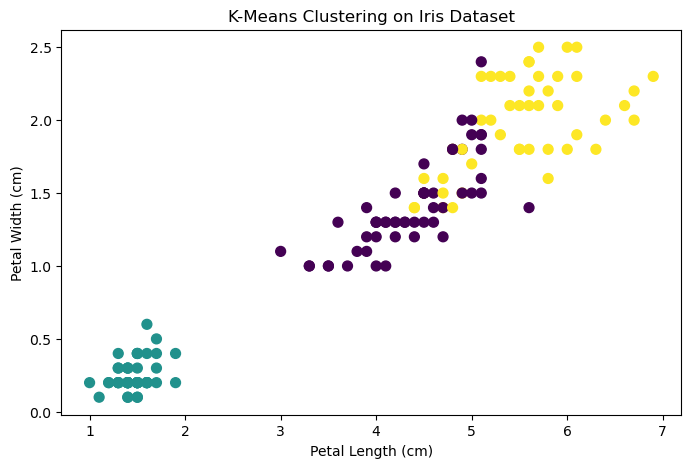


Actual species vs predicted clusters:
Cluster          0   1   2
Actual Species            
setosa           0  50   0
versicolor      39   0  11
virginica       14   0  36

Adjusted Rand Index: 0.6201351808870379


In [10]:

# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score


# 2. Load the Iris dataset

iris = load_iris(as_frame=True)
X = iris.data

print("First five rows:")
print(X.head())

print("\nDataset shape:", X.shape)


# 3. Scale the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 4. Create the K-Means model

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)


# 5. Fit the model and predict clusters

clusters = kmeans.fit_predict(X_scaled)


# 6. Display the cluster assignments

results = X.copy()
results["Cluster"] = clusters

print("\nCluster assignments:")
print(results.head(10))

print("\nNumber of flowers in each cluster:")
print(results["Cluster"].value_counts().sort_index())


# 7. Visualize the clusters

plt.figure(figsize=(8, 5))

plt.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clustering on Iris Dataset")
plt.show()


# 8. Compare with actual species (evaluation only)

print("\nActual species vs predicted clusters:")

print(pd.crosstab(
    iris.target_names[iris.target],
    clusters,
    rownames=["Actual Species"],
    colnames=["Cluster"]
))

ari = adjusted_rand_score(iris.target, clusters)
print("\nAdjusted Rand Index:", ari)
